# NutriLens AI: Notebook 2 — Dataset Preprocessing & Stratification

**Project:** NutriLens AI — AI-Powered Food Recognition and Nutrition Analysis  
**Author:** NutriLens AI Engineering Team  
**Dataset:** `SohlHealth/enhanced-indian-food-classification` (Hugging Face)  
**Target Environment:** Google Colab (with GPU acceleration) / Local Jupyter

---

### Objectives:
1. **Load Dataset:** Stream and load all 15,404 samples from Hugging Face.
2. **Remedy Upstream Split Defect:** Pool all samples and create a clean, reproducible, stratified 70/15/15 train/validation/test split across all 43 classes.
3. **Prevent Data Leakage:** Ensure zero overlap between train, validation, and test subsets.
4. **Handle Class Imbalance:** Compute inverse-frequency class weights for cost-sensitive CrossEntropyLoss to counteract the 6.24:1 majority-minority imbalance.
5. **Data Augmentation Pipeline:** Build domain-appropriate augmentation transforms for Indian cuisine (rotations, flips, color jitter, subtle scaling) while preserving food characteristics.
6. **PyTorch DataLoaders:** Construct optimized PyTorch `Dataset` and `DataLoader` instances with pinned memory and multi-worker prefetching.
7. **Export Preprocessing Artifacts:** Export stratified split metadata and class weights for seamless import into Notebook 3.


## 1. Environment Setup & Dependency Installation

In [1]:
!pip install --quiet datasets huggingface_hub pyarrow pillow matplotlib seaborn pandas scikit-learn tqdm torch torchvision

import os
import sys
import json
import random
from io import BytesIO
from collections import Counter

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from PIL import Image
from tqdm.auto import tqdm
from sklearn.model_selection import train_test_split

import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader
import torchvision.transforms as transforms

# Set reproducible random seeds
SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

device = "cuda" if torch.cuda.is_available() else "cpu"
print(f"PyTorch Version: {torch.__version__}")
print(f"Device: {device}")
if device == "cuda":
    print(f"GPU: {torch.cuda.get_device_name(0)}")



[notice] A new release of pip is available: 26.2.1 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


PyTorch Version: 2.11.0+cpu
Device: cpu


## 2. Load Dataset & Pool Flawed Upstream Splits

In Phase 1, we discovered that the upstream Hugging Face repository has a severe flaw:
- The `validation` split contains only 22 of 43 classes.
- The `test` split contains the exact same 22 classes.
- 21 classes (6,000 images) are present only in `train`.

To train and evaluate scientifically without bias or missing evaluation metrics, we must pool all 15,404 samples and re-partition them with stratified sampling across **all 43 classes**.


In [2]:
from datasets import load_dataset, concatenate_datasets

DATASET_REPO = "SohlHealth/enhanced-indian-food-classification"
print(f"Loading all splits from Hugging Face: {DATASET_REPO}...")
raw_ds = load_dataset(DATASET_REPO)

# Pool train, validation, and test into a single unified dataset
all_splits = [raw_ds[split] for split in raw_ds.keys()]
pooled_dataset = concatenate_datasets(all_splits)

print(f"\nPooled Dataset Size: {len(pooled_dataset):,} samples")
print(f"Features: {pooled_dataset.features}")


Loading all splits from Hugging Face: SohlHealth/enhanced-indian-food-classification...



Pooled Dataset Size: 15,404 samples
Features: {'image': Image(mode=None, decode=True), 'label': Value('string')}


## 3. Stratified 70 / 15 / 15 Train, Validation, Test Split

We perform a two-stage stratified split:
1. Split pooled dataset into **Train (70%)** and **Temporary (30%)** stratified by class label.
2. Split Temporary into **Validation (15%)** and **Test (15%)** stratified by class label.


In [3]:
# Extract all indices and labels
all_labels = [item["label"] for item in pooled_dataset]
all_indices = np.arange(len(pooled_dataset))

unique_classes = sorted(list(set(all_labels)))
class_to_idx = {cls: idx for idx, cls in enumerate(unique_classes)}
idx_to_class = {idx: cls for idx, cls in enumerate(unique_classes)}
num_classes = len(unique_classes)

print(f"Total Unique Classes: {num_classes}")

# Step 1: 70% Train, 30% Temp (Val + Test)
train_idx, temp_idx, train_y, temp_y = train_test_split(
    all_indices,
    all_labels,
    test_size=0.30,
    stratify=all_labels,
    random_state=SEED
)

# Step 2: Split 30% Temp equally into 15% Validation and 15% Test
val_idx, test_idx, val_y, test_y = train_test_split(
    temp_idx,
    temp_y,
    test_size=0.50,
    stratify=temp_y,
    random_state=SEED
)

print("\n--- Stratified Split Summary ---")
print(f"Train samples:      {len(train_idx):,} ({len(train_idx)/len(all_indices)*100:.1f}%)")
print(f"Validation samples: {len(val_idx):,} ({len(val_idx)/len(all_indices)*100:.1f}%)")
print(f"Test samples:       {len(test_idx):,} ({len(test_idx)/len(all_indices)*100:.1f}%)")
print(f"Total:              {len(train_idx) + len(val_idx) + len(test_idx):,}")


Total Unique Classes: 43

--- Stratified Split Summary ---
Train samples:      10,782 (70.0%)
Validation samples: 2,311 (15.0%)
Test samples:       2,311 (15.0%)
Total:              15,404


### Verify Class Coverage in All Splits

In [4]:
train_counts = Counter(train_y)
val_counts = Counter(val_y)
test_counts = Counter(test_y)

split_audit = []
for cls in unique_classes:
    split_audit.append({
        "Class": cls,
        "Train Count": train_counts.get(cls, 0),
        "Val Count": val_counts.get(cls, 0),
        "Test Count": test_counts.get(cls, 0),
        "Total": train_counts.get(cls, 0) + val_counts.get(cls, 0) + test_counts.get(cls, 0)
    })

df_audit = pd.DataFrame(split_audit)

# Verify zero classes are missing
missing_train = df_audit[df_audit["Train Count"] == 0]
missing_val = df_audit[df_audit["Val Count"] == 0]
missing_test = df_audit[df_audit["Test Count"] == 0]

print(f"Classes missing in Train:      {len(missing_train)}")
print(f"Classes missing in Validation: {len(missing_val)}")
print(f"Classes missing in Test:       {len(missing_test)}")

print("\nSample Class Proportions across Splits:")
print(df_audit.head(10).to_string(index=False))


Classes missing in Train:      0
Classes missing in Validation: 0
Classes missing in Test:       0

Sample Class Proportions across Splits:
        Class  Train Count  Val Count  Test Count  Total
    aloo_gobi          140         30          30    200
  aloo_masala          140         30          30    200
bhindi_masala          280         60          60    400
      biryani          280         60          60    400
       burger          216         47          46    309
  butter_naan          230         50          49    329
         chai          407         87          87    581
      chapati          429         92          92    613
chicken_curry          140         30          30    200
        chole          280         60          60    400


## 4. Handling Class Imbalance: Compute Class Weights

Because class frequencies range from 130 (`paani_puri`) to 811 (`chole_bhature`), unweighted loss would bias the network toward majority classes.
We compute cost-sensitive class weights using inverse class frequency:
$$w_c = \frac{N}{C \cdot N_c}$$
where $N$ is total training samples, $C$ is number of classes, and $N_c$ is count of samples in class $c$.


In [5]:
total_train_samples = len(train_idx)
class_weights_list = []

for cls in unique_classes:
    nc = train_counts.get(cls, 1)
    weight = total_train_samples / (num_classes * nc)
    class_weights_list.append(weight)

class_weights_tensor = torch.tensor(class_weights_list, dtype=torch.float32)

print("Class Weights Calculated:")
print(f"  - Max weight (rarest class): {class_weights_tensor.max().item():.3f} ({unique_classes[class_weights_tensor.argmax()]})")
print(f"  - Min weight (most frequent): {class_weights_tensor.min().item():.3f} ({unique_classes[class_weights_tensor.argmin()]})")
print(f"  - Weight ratio: {class_weights_tensor.max().item() / class_weights_tensor.min().item():.2f}x")


Class Weights Calculated:
  - Max weight (rarest class): 2.755 (paani_puri)
  - Min weight (most frequent): 0.441 (chole_bhature)
  - Weight ratio: 6.24x


## 5. Data Augmentation & Normalization Pipeline

We design a domain-appropriate augmentation pipeline for Indian dishes:
1. **RandomResizedCrop(224, scale=(0.8, 1.0)):** Simulates varied camera distance and plate angles without losing major dish portions.
2. **RandomHorizontalFlip(p=0.5):** Food plates are symmetric; horizontal flip generates valid synthetic samples.
3. **RandomRotation(degrees=15):** Accommodates hand-held smartphone photo tilts.
4. **ColorJitter(brightness=0.15, contrast=0.15, saturation=0.15):** Handles indoor restaurant lighting variances.
5. **ImageNet Normalization:** Normalizes RGB channels using mean `[0.485, 0.456, 0.406]` and std `[0.229, 0.224, 0.225]`.


In [6]:
train_transform = transforms.Compose([
    transforms.RandomResizedCrop(224, scale=(0.8, 1.0)),
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.RandomRotation(degrees=15),
    transforms.ColorJitter(brightness=0.15, contrast=0.15, saturation=0.15),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
])

val_test_transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
])

print("Augmentation and validation transforms constructed successfully.")


Augmentation and validation transforms constructed successfully.


## 6. PyTorch Dataset and DataLoader Implementation

In [7]:
class IndianFoodDataset(Dataset):
    """PyTorch Dataset wrapping Hugging Face samples with custom transforms."""
    def __init__(self, hf_dataset, indices, class_to_idx, transform=None):
        self.dataset = hf_dataset
        self.indices = indices
        self.class_to_idx = class_to_idx
        self.transform = transform

    def __len__(self):
        return len(self.indices)

    def __getitem__(self, idx):
        real_idx = int(self.indices[idx])
        sample = self.dataset[real_idx]
        image = sample["image"]
        
        if image.mode != "RGB":
            image = image.convert("RGB")
            
        label_str = sample["label"]
        label_idx = self.class_to_idx[label_str]

        if self.transform:
            image = self.transform(image)

        return image, label_idx

# Create Dataset instances
train_dataset = IndianFoodDataset(pooled_dataset, train_idx, class_to_idx, transform=train_transform)
val_dataset = IndianFoodDataset(pooled_dataset, val_idx, class_to_idx, transform=val_test_transform)
test_dataset = IndianFoodDataset(pooled_dataset, test_idx, class_to_idx, transform=val_test_transform)

# Create DataLoader instances
BATCH_SIZE = 32
NUM_WORKERS = 2 if torch.cuda.is_available() else 0

train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=NUM_WORKERS,
    pin_memory=torch.cuda.is_available()
)

val_loader = DataLoader(
    val_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=NUM_WORKERS,
    pin_memory=torch.cuda.is_available()
)

test_loader = DataLoader(
    test_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=NUM_WORKERS,
    pin_memory=torch.cuda.is_available()
)

print(f"DataLoaders Ready:")
print(f"  - Train batches: {len(train_loader)} (Batch size: {BATCH_SIZE})")
print(f"  - Val batches:   {len(val_loader)}")
print(f"  - Test batches:  {len(test_loader)}")


DataLoaders Ready:
  - Train batches: 337 (Batch size: 32)
  - Val batches:   73
  - Test batches:  73


## 7. Visualizing Original vs. Augmented Images

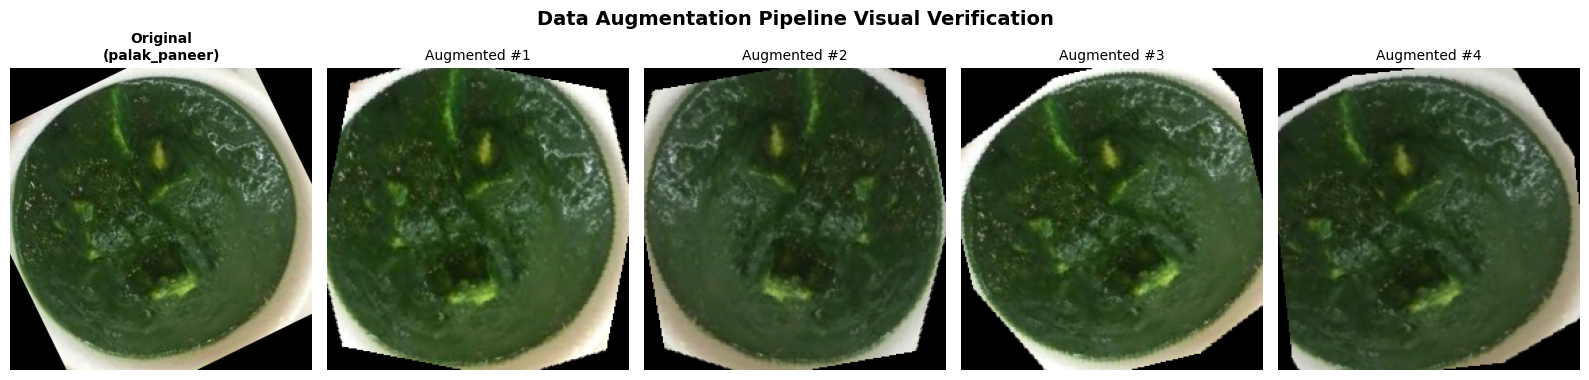

In [8]:
# Display unaugmented vs 4 augmented versions of a single food sample
sample_raw_idx = int(train_idx[0])
sample_img = pooled_dataset[sample_raw_idx]["image"].convert("RGB")
sample_label = pooled_dataset[sample_raw_idx]["label"]

inv_normalize = transforms.Normalize(
    mean=[-0.485/0.229, -0.456/0.224, -0.406/0.225],
    std=[1/0.229, 1/0.224, 1/0.225]
)

fig, axes = plt.subplots(1, 5, figsize=(16, 4))
axes[0].imshow(sample_img)
axes[0].set_title(f"Original\n({sample_label})", fontsize=10, fontweight="bold")
axes[0].axis("off")

for i in range(1, 5):
    aug_tensor = train_transform(sample_img)
    denorm = inv_normalize(aug_tensor).permute(1, 2, 0).numpy()
    denorm = np.clip(denorm, 0, 1)
    axes[i].imshow(denorm)
    axes[i].set_title(f"Augmented #{i}", fontsize=10)
    axes[i].axis("off")

plt.suptitle("Data Augmentation Pipeline Visual Verification", fontsize=14, fontweight="bold")
plt.tight_layout()
plt.show()


## 8. Export Preprocessing Artifacts for Model Training

In [9]:
os.makedirs("../data", exist_ok=True)
os.makedirs("../models", exist_ok=True)

# Export split indices and class weights
preprocessing_metadata = {
    "num_samples_total": len(pooled_dataset),
    "train_indices_count": len(train_idx),
    "val_indices_count": len(val_idx),
    "test_indices_count": len(test_idx),
    "random_seed": SEED,
    "batch_size": BATCH_SIZE,
    "num_classes": num_classes,
    "class_names": unique_classes,
    "class_weights": class_weights_list
}

with open("../data/preprocessing_metadata.json", "w", encoding="utf-8") as f:
    json.dump(preprocessing_metadata, f, indent=2)

# Save class weights as torch tensor
torch.save(class_weights_tensor, "../models/class_weights.pt")

# Save split indices for exact reproducibility in Notebook 3
np.savez(
    "../data/split_indices.npz",
    train_idx=train_idx,
    val_idx=val_idx,
    test_idx=test_idx
)

print("Exported:")
print("  - ../data/preprocessing_metadata.json")
print("  - ../models/class_weights.pt")
print("  - ../data/split_indices.npz")
print("\nNotebook 2 Preprocessing Complete! Ready for Notebook 3 (Model Training).")


Exported:
  - ../data/preprocessing_metadata.json
  - ../models/class_weights.pt
  - ../data/split_indices.npz

Notebook 2 Preprocessing Complete! Ready for Notebook 3 (Model Training).
